# Virtual iEEG

Projects source-reconstructed activity, via a simplified forward model, onto the channel positions of the true intracranial recording (Grova et al. 2016's virtual-electrode methodology), then compares the reconstruction against the real iEEG on spatial and temporal *pattern fidelity* -- not the localization-error metrics Grova et al. originally proposed. Per-mode correlation and cosine similarity (spatial/temporal/spatio-temporal), explained variance, and REM (relative energy map) correlation are compared across 5 source reconstruction methods (`wcset`, `sloreta`, `cset`, `dspm`, `mce`), both as aggregate scores and as win-rate matrices -- the fraction of channels/timepoints where one method's per-channel or per-timepoint score beats another's, which an averaged score alone can hide.

## 🧪 - Experiment setup
- `src`: Source spaces
- `i-ave`: Average intracranial recording
- `wcset`, `sloreta`, `cset`, `dspm`, `mce`: Source estimates from the 5 compared reconstruction methods

In [1]:
# imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

import mindmap as mm

# reader
dm = mm.io.TutoManager("../../config.yml")
sub = "intra48"

# data
src = dm.load(sub, "fwd")["src"]
ieeg = dm.load(sub, "i-ave", task="spk")
wcset = dm.load(sub, "stc", task="spk", desc="wcset")
sloreta = dm.load(sub, "stc", task="spk", desc="sloreta")
cset = dm.load(sub, "stc", task="spk", desc="cset")
dspm = dm.load(sub, "stc", task="spk", desc="dspm")
mce = dm.load(sub, "stc", task="spk", desc="mce")

## 🧬 - Data Processing
Estimate spike generation extent and spurious areas
`extent_mask`: Mask of channels in spike extent area.
`spurious_mask`: Mask for channels in spurious area.

In [2]:
# estimate spike generation extent zone and spurious zone
extent_mask = mm.core.get_spike_extent_mask(
    ieeg.data.T, 
    perc_max_amp=0.7
)

spurious_mask = mm.core.get_spurious_mask(
    extent_mask,
    mm.analysis.eeg.get_ch_positions(ieeg),
    spurious_dist=0.01
)

Virtual electrodes: project each of the 5 source estimates onto the true iEEG channel positions.
`v`: dict of virtual electrodes, one per method (`v["wcset"]`, `v["sloreta"]`, `v["cset"]`, `v["dspm"]`, `v["mce"]`)

In [3]:
stcs = {"wcset": wcset, "sloreta": sloreta, "cset": cset, "dspm": dspm, "mce": mce}

v = {
    name: mm.analysis.eeg.compute_virtual_ieeg(
        src, stc, ieeg,
        conductivity = 0.25,
        threshold = 0.003,
    )
    for name, stc in stcs.items()
}
v_wcset, v_sloreta, v_cset, v_dspm, v_mce = (v[name] for name in stcs)

## 📏 - Fidelity Metrics
Instead of the Grova et al. localization metrics, compare `wcset` and `sloreta` on how well they reconstruct the true iEEG's spatial and temporal *pattern*: correlation & cosine (spatial, temporal, spatio-temporal), a representational-similarity-style spatial pattern-geometry comparison, explained variance, SSIM, and a relative-energy-map comparison. Computed over the GFP-detected spike window only (`find_spike_window`), not the whole baseline+spike epoch.

In [4]:
# normalize data for visualizations
ieeg_norm = mm.analysis.eeg.normalize_evoked_by_baseline(ieeg, baseline=(0, 1.0))
v_norms = {
    name: mm.analysis.eeg.normalize_evoked_by_baseline(evoked, baseline=(0, 1.0))
    for name, evoked in v.items()
}
v_wcset_norm, v_sloreta_norm, v_cset_norm, v_dspm_norm, v_mce_norm = (v_norms[name] for name in stcs)

# restrict metrics to the actual signal window (GFP above baseline std, with
# gap-filling/min-duration cleanup), not the whole baseline+spike epoch.
# baseline is in [s] here, matching normalize_evoked_by_baseline above --
# despite find_spike_window's docstring claiming milliseconds, its code
# compares directly against evoked.times, which MNE always stores in seconds.
tmin, tmax = mm.analysis.eeg.find_spike_window(ieeg, baseline=(0, 1.0))

ieeg_win = ieeg_norm.copy().crop(tmin, tmax)
v_wins = {name: evoked.copy().crop(tmin, tmax) for name, evoked in v_norms.items()}
v_wcset_win, v_sloreta_win, v_cset_win, v_dspm_win, v_mce_win = (v_wins[name] for name in stcs)

In [5]:
metrics = mm.metric.MetricSuite("Virtual iEEG Fidelity")

for method, v_win in v_wins.items():
    for mode, coords in [
        ("spatial", {"times": v_win.times}),
        ("temporal", {"channel": v_win.ch_names}),
        ("spatio-temporal", {}),
    ]:
        # polarity_invariant=True: channel polarity is an arbitrary reference/
        # orientation convention here, not a meaningful failure mode -- an
        # overall sign flip shouldn't score worse than a perfectly in-phase match.
        metrics.register(
            f"correlation_{mode}",
            mm.analysis.eeg.compute_evoked_correlation(ieeg_win, v_win, mode=mode, polarity_invariant=True),
            Label=method, **coords,
        )
        metrics.register(
            f"cosine_{mode}",
            mm.analysis.eeg.compute_evoked_cosine(ieeg_win, v_win, mode=mode, polarity_invariant=True),
            Label=method, **coords,
        )

    metrics.register("explained_variance",
                      mm.analysis.eeg.compute_evoked_explained_variance(ieeg_win, v_win, polarity_invariant=True),
                      Label=method)
    # rem_correlation_{mode}: mirrors correlation_{mode}/cosine_{mode}'s naming --
    # REM has no polarity_invariant option (see calc_explained_variance's docstring
    # for why abs()-of-score doesn't work for non-correlation metrics; REM is
    # already polarity-invariant by construction, being built from squared energy).
    metrics.register("rem_correlation_temporal",
                      mm.analysis.eeg.compute_evoked_rem_correlation(ieeg_win, v_win, mode="temporal"),
                      Label=method, channel=v_win.ch_names)
    metrics.register("rem_correlation_spatial",
                      mm.analysis.eeg.compute_evoked_rem_correlation(ieeg_win, v_win, mode="spatial"),
                      Label=method, times=v_win.times)

In [ ]:
# one metric per call now (see mindmap's plotting API) -- loop over every
# registered metric onto our own grid instead of relying on a general .plot()
# to facet them for us. suite.plot.box draws a box per group (no bar-chart
# style available in the current plotting API).
metric_names = metrics.to_df()["Metric"].unique()
n_cols = 3
n_rows = -(-len(metric_names) // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
for ax, metric_name in zip(axes.flat, metric_names):
    metrics.plot.box(metric=metric_name, group_by="Label", ax=ax)
for ax in axes.flat[len(metric_names):]:
    ax.set_visible(False)
fig.tight_layout()

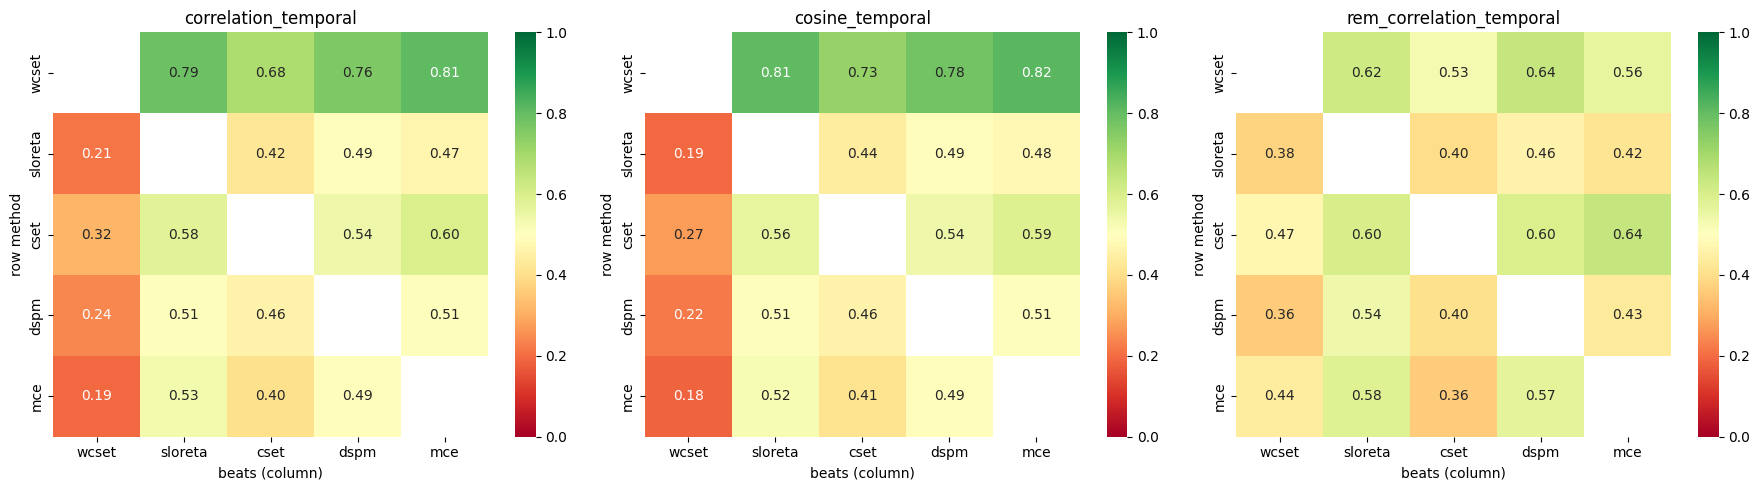

In [7]:
# win-rate matrix: for every pair of methods, what fraction of channels does
# the row-method beat the column-method on? Compresses all C(5,2)=10 pairwise
# per-channel comparisons into one view per metric -- same "count of channels
# improved" idea as an averaged score can hide, extended to all method pairs
# at once, with no reference method to pick.
per_channel_metrics = ["correlation_temporal", "cosine_temporal", "rem_correlation_temporal"]
method_names = list(v_wins.keys())

df_all = metrics.to_df(metrics=per_channel_metrics)

fig, axes = plt.subplots(1, len(per_channel_metrics), figsize=(6 * len(per_channel_metrics), 5))
for ax, metric_name in zip(axes, per_channel_metrics):
    sub_df = df_all[df_all["Metric"] == metric_name]
    pivoted = sub_df.pivot(index="channel", columns="Label", values="Value")[method_names]

    win_rate = pd.DataFrame(index=method_names, columns=method_names, dtype=float)
    for row_method in method_names:
        for col_method in method_names:
            win_rate.loc[row_method, col_method] = (
                np.nan if row_method == col_method
                else (pivoted[row_method] > pivoted[col_method]).mean()
            )

    sns.heatmap(win_rate, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, cbar=True)
    ax.set_title(metric_name)
    ax.set_xlabel("beats (column)")
    ax.set_ylabel("row method")

plt.tight_layout()

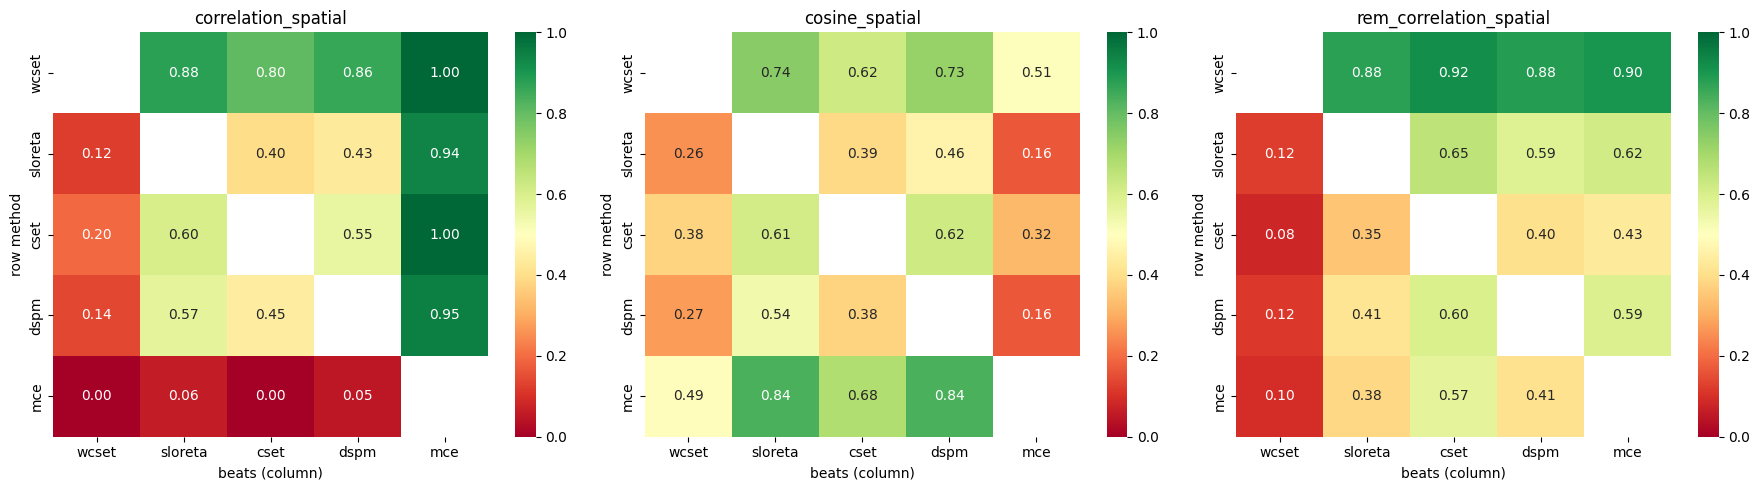

In [8]:
# same win-rate idea, applied to timepoints instead of channels: for every
# pair of methods, what fraction of timepoints does the row-method beat the
# column-method on. Note this is a coarser summary than the channel version --
# timepoints within the window are highly autocorrelated (unlike channels,
# which are more independent spatial units), so this says "how often" a
# method wins, not "when" (e.g. near the spike peak vs. a weaker segment).
per_timepoint_metrics = ["correlation_spatial", "cosine_spatial", "rem_correlation_spatial"]

df_time = metrics.to_df(metrics=per_timepoint_metrics)

fig, axes = plt.subplots(1, len(per_timepoint_metrics), figsize=(6 * len(per_timepoint_metrics), 5))
for ax, metric_name in zip(axes, per_timepoint_metrics):
    sub_df = df_time[df_time["Metric"] == metric_name]
    pivoted = sub_df.pivot(index="times", columns="Label", values="Value")[method_names]

    # sanity check: pivoting on a float coordinate (unlike "channel", a string)
    # could silently produce NaNs if the "times" values weren't bit-identical
    # across methods -- they should be, since every method's evoked was cropped
    # from the same tmin/tmax on the same original sampling grid.
    assert not pivoted.isna().any().any(), "times didn't align cleanly across methods -- check crop consistency"

    win_rate = pd.DataFrame(index=method_names, columns=method_names, dtype=float)
    for row_method in method_names:
        for col_method in method_names:
            win_rate.loc[row_method, col_method] = (
                np.nan if row_method == col_method
                else (pivoted[row_method] > pivoted[col_method]).mean()
            )

    sns.heatmap(win_rate, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax, cbar=True)
    ax.set_title(metric_name)
    ax.set_xlabel("beats (column)")
    ax.set_ylabel("row method")

plt.tight_layout()

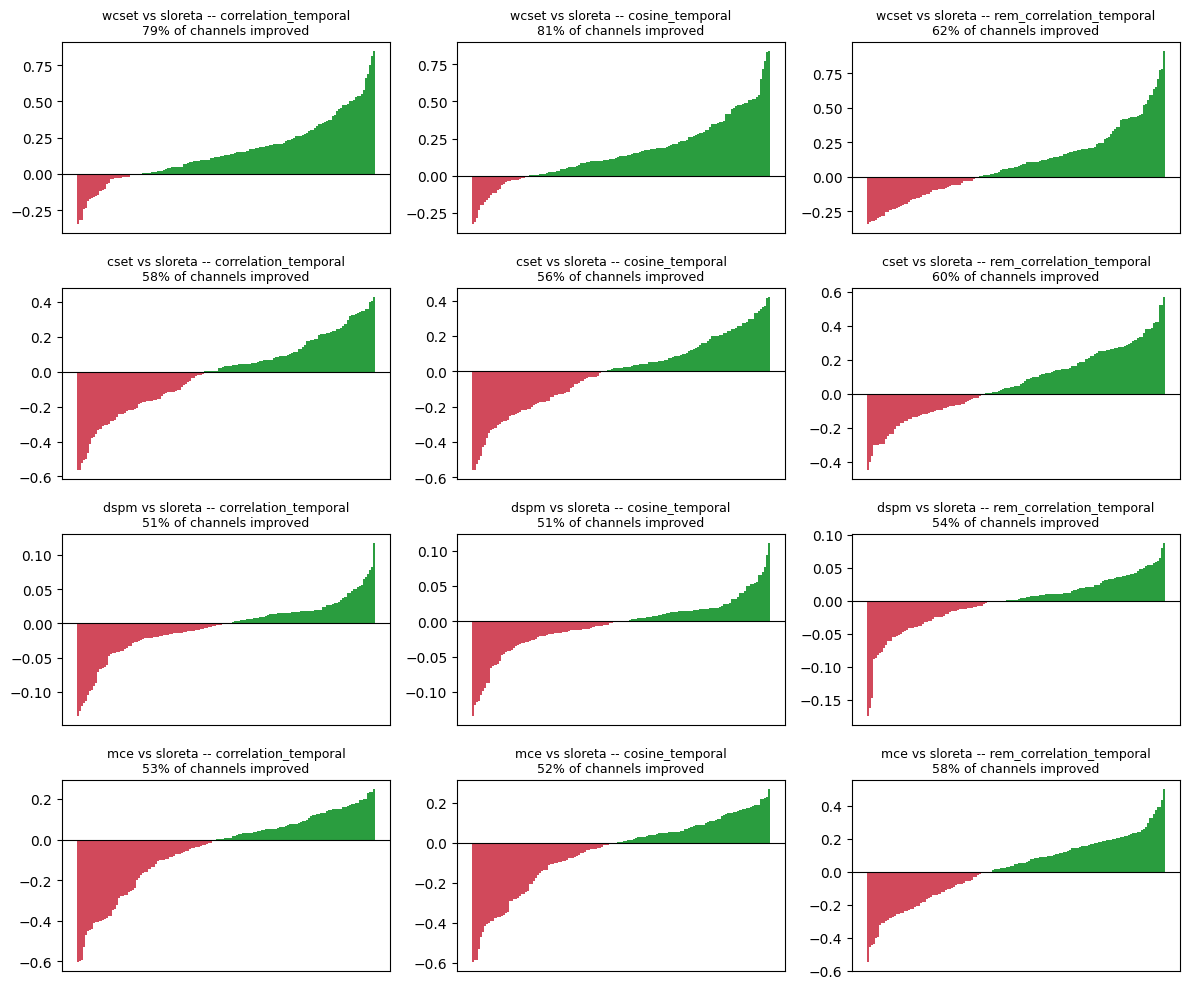

In [9]:
# reference-relative diff, shown as a sorted per-channel distribution rather
# than vs. a covariate -- same computation as the wcset-vs-sloreta diff plot
# above, repeated for every other method against one reference (sloreta, the
# classic baseline), so the "how many channels improved" read carries over
# to all 5 methods without needing 10 pairwise panels.
reference_method = "sloreta"
other_methods = [m for m in method_names if m != reference_method]

diff_rows = []
for metric_name in per_channel_metrics:
    sub_df = df_all[df_all["Metric"] == metric_name]
    pivoted = sub_df.pivot(index="channel", columns="Label", values="Value")

    for method in other_methods:
        diff = pivoted[method] - pivoted[reference_method]
        diff_rows.append(pd.DataFrame({"Metric": metric_name, "Method": method, "diff": diff.values}))

ref_diff_df = pd.concat(diff_rows, ignore_index=True)

fig, axes = plt.subplots(
    len(other_methods), len(per_channel_metrics),
    figsize=(4 * len(per_channel_metrics), 2.5 * len(other_methods)),
)
for i, method in enumerate(other_methods):
    for j, metric_name in enumerate(per_channel_metrics):
        ax = axes[i, j]
        sorted_diff = np.sort(
            ref_diff_df.loc[(ref_diff_df["Method"] == method) & (ref_diff_df["Metric"] == metric_name), "diff"].values
        )
        colors = ["#2a9d3f" if d > 0 else "#d1495b" for d in sorted_diff]
        ax.bar(range(len(sorted_diff)), sorted_diff, color=colors, width=1.0)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks([])
        pct_improved = (sorted_diff > 0).mean() * 100
        ax.set_title(f"{method} vs {reference_method} -- {metric_name}\n{pct_improved:.0f}% of channels improved", fontsize=9)

plt.tight_layout()

## 📊 - Visualization
Channel position

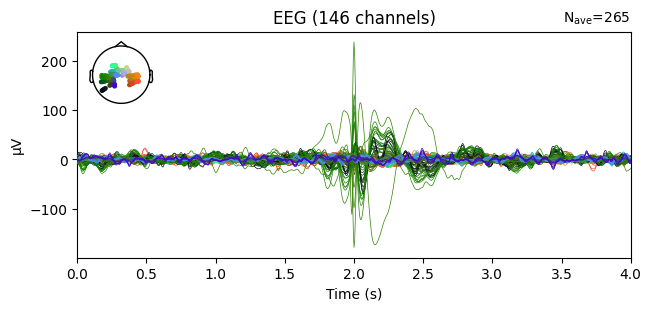

In [10]:
ieeg.plot();

In [11]:
from mindmap.viz.dispatch import plot_ieeg

plot_ieeg(src, ieeg, extent_mask, spurious_mask, subject=sub, ts_params={"absolute":True}).show()

Widget(value='<iframe src="http://localhost:44967/index.html?ui=P_0x7f5bf63fb350_0&reconnect=auto" class="pyvi…

Source reconstructions

In [12]:
mm.viz.plot_brain_activity(src, list(stcs.values()), func_params={"normalize":"max", "absolute":True}).show()

Widget(value='<iframe src="http://localhost:44967/index.html?ui=P_0x7f5bd87922d0_1&reconnect=auto" class="pyvi…

Global field power

/tmp/ipykernel_48560/396978865.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ).show()


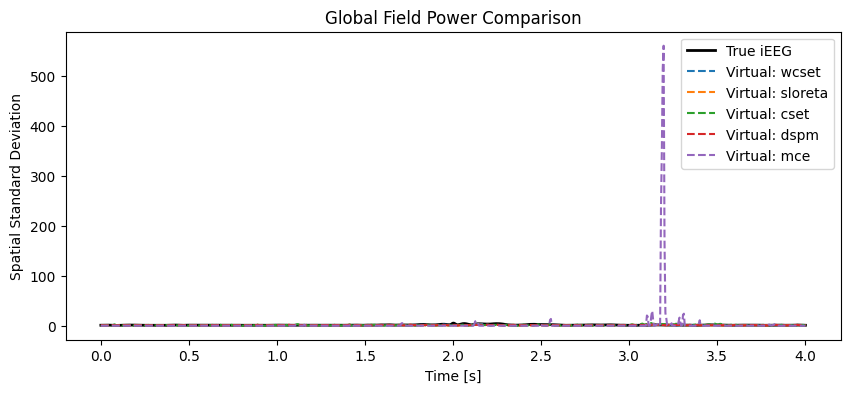

In [13]:
# plot the global field power (gfp)
mm.viz.plot_gfp_comparison(
    ieeg_norm,
    dict_of_evoked_est = v_norms,
).show()

Individual averaged channels

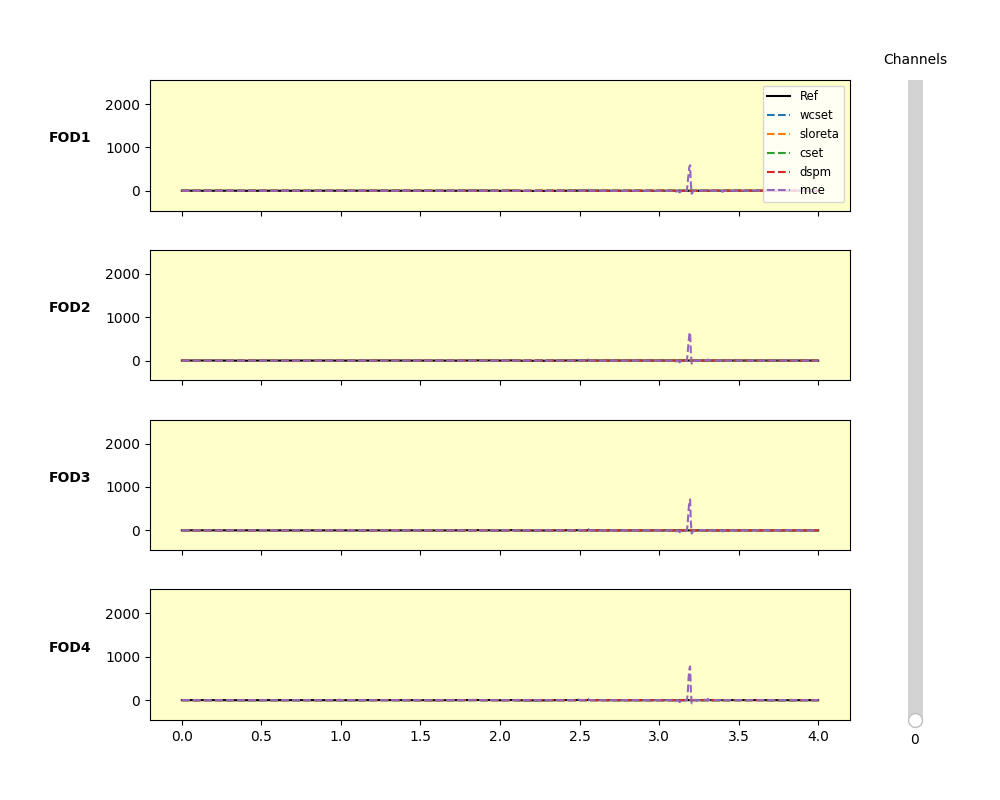

In [14]:
%matplotlib widget


# plot individual channels
_ = mm.viz.plot_channel_grid(ieeg_norm, v_norms, extent_mask, spurious_mask)